## Summary Plots and Tables

In [28]:
import matplotlib.pyplot as plt
import numpy as np
import scienceplots
import os

from kernelprob.configs.config import *
from kernelprob.utils.datasets import dataset_sizes

plt.style.use('science')

# Load in files into a giant dictionary
# filename format: dataset_estimator_weighting
dataset_names = DATASETS['small_n'] + DATASETS['big_n']


all_weights = [
    'beta_shapley_2_2', 'beta_shapley_4_4', 'beta_shapley_8_8', 'beta_shapley_16_16',
    'beta_shapley_1_2', 'beta_shapley_1_4', 'beta_shapley_1_8', 'beta_shapley_1_16',
    'weighted_banzhaf_0.5', 'weighted_banzhaf_0.6', 'weighted_banzhaf_0.7', 'weighted_banzhaf_0.8', 'weighted_banzhaf_0.9',
    'beta_shapley_1_1', 
    'banzhaf', # Important to include this last
    'shapley' # Important to include this last
]

weight_lookup = {
    'beta_shapley_1_1' : 'B(1,1)',
    'beta_shapley_2_2' : 'B(2,2)',
    'beta_shapley_4_4' : 'B(4,4)',
    'beta_shapley_8_8' : 'B(8,8)',
    'beta_shapley_16_16' : 'B(16,16)',
    'beta_shapley_1_2' : 'B(1,2)',
    'beta_shapley_1_4' : 'B(1,4)',
    'beta_shapley_1_8' : 'B(1,8)',
    'beta_shapley_1_16' : 'B(1,16)',
    'weighted_banzhaf_0.5' : 'WB(0.5)',
    'weighted_banzhaf_0.6' : 'WB(0.6)',
    'weighted_banzhaf_0.7' : 'WB(0.7)',
    'weighted_banzhaf_0.8' : 'WB(0.8)',
    'weighted_banzhaf_0.9' : 'WB(0.9)',
    'banzhaf' : 'Banzhaf',
    'shapley' : 'Shapley',
}

weightings = {
    'Symmetric Beta' :
        ['beta_shapley_1_1', 'beta_shapley_2_2', 'beta_shapley_4_4', 'beta_shapley_8_8', 'beta_shapley_16_16'],
    'Asymmetric Beta' : 
        ['beta_shapley_1_1', 'beta_shapley_1_2', 'beta_shapley_1_4', 'beta_shapley_1_8', 'beta_shapley_1_16'],
    'Weighted Banzhaf' : 
        ['weighted_banzhaf_0.5', 'weighted_banzhaf_0.6', 'weighted_banzhaf_0.7', 'weighted_banzhaf_0.8', 'weighted_banzhaf_0.9']
}

def extract_helper(filename, valid_names):
    filename = filename.replace('.csv', '').replace('OFA_S', 'OFAS').split('_', 2)
    if 'OFAS' in filename[0]:
        filename[0] = filename[0].replace('OFAS', 'OFA_S')
    for name in valid_names:
        if name in filename:
            return name
    raise ValueError(f'Could not find any of {valid_names} in filename {filename}')

def load_filtered_error(filter, extra_variable = None):
    results = {}
    filenames = os.listdir('output')
    for filename in filenames:
        if filename == '.DS_Store' or 'fit_' in filename or 'case_study_' in filename: continue
        # The challenge is that there are extra underscores in the filename that we need to account for
        dataset = extract_helper(filename, dataset_names)
        estimator = extract_helper(filename, ESTIMATOR_FACTORY.keys())
        weighting = extract_helper(filename, all_weights)

        # Load in the file
        with open(f'output/{filename}', 'r') as f:
            # Each line is a dictionary, we want to e
            for line in f:
                if 'inf' in line or 'nan' in line: continue
                line = eval(line)
                # Check if the line is valid
                if 'sample_size' in filter:
                    if line['sample_size'] // line['n'] not in filter['sample_size']:
                        continue
                if 'noise' in filter:
                    if line['noise'] not in filter['noise']:
                        continue
                # Add to the results
                if dataset not in results:
                    results[dataset] = {}
                if weighting not in results[dataset]:
                    results[dataset][weighting] = {}
                if estimator not in results[dataset][weighting]:
                    if extra_variable is None:
                        results[dataset][weighting][estimator] = []
                    else:
                        results[dataset][weighting][estimator] = {}
                if extra_variable is None:
                    results[dataset][weighting][estimator].append(line['error'])
                else:
                    if line[extra_variable] not in results[dataset][weighting][estimator]:
                        results[dataset][weighting][estimator][line[extra_variable]] = []  
                    results[dataset][weighting][estimator][line[extra_variable]].append(line['error'])
                    
    return results

def load_fit_error(dataset, ground_truth_class):
    filename = f'output/fit_{dataset}.csv'
    errors = {
        'Linear' : {}, 'RandomForest' : {}, 'XGBoost' : {}
    }
    with open(filename, 'r') as f:
        for line in f:
            dict = eval(line)
            if dict['ground_truth_class'] != ground_truth_class:
                continue
            sm, rm = dict['sample_multiplier'], dict['reg_model_class']
            if sm not in errors[rm]:
                errors[rm][sm] = []
            errors[rm][sm].append(dict['error'])
    return errors

In [29]:
# Colors and linestyles for accessible plots
cb_colors = [
    "#D55E00",  # Vermillion
    "#56B4E9",  # Sky Blue
    "#44AA99",  # Teal
    "#AA4499",  # Magenta
    "#009E73",  # Bluish Green
    "#0072B2",  # Blue
    "#E69F00",  # Orange
    "#CC79A7",  # Reddish Purple
    "#F0E442",  # Yellow
    "#999999",  # Gray
    "#882255",  # Dark Red-Purple
    "#117733",  # Forest Green
    "#88CCEE",  # Light Cyan
    "#CC6677",  # Coral Pink
    "#332288",  # Dark Navy
]

linestyles = [
    '-',               # Solid Line
    '--',              # Dashed Line
    '-.',              # Dash-Dot Line
    (0, (1, 1)),       # Dense Dots
    ':',               # Dotted Line
    (0, (1, 10)),      # Dash-Dot with large gaps
    (0, (5, 10)),      # Long Dashes
    (0, (3, 1, 1, 1)), # Dense Dash-Dot
    (0, (3, 5, 1, 5)), # Dash-Dot with medium gaps
    (0, (10, 1)),      # Very Long Dashes
    (0, (5, 2, 1, 2)), # Custom Dense Pattern
    (0, (7, 3)),       # Long Dash with Gaps
    (0, (2, 2, 10, 2)),# Double Dash with Gap
    (0, (4, 4, 1, 4)), # Dash-Dot-Dot
    (0, (6, 2, 1, 2)), # Custom Alternating
]

### Shapley Values

In [30]:
use_estimators = [
    'KernelSHAP',
    'PermutationSHAP',
    'LeverageSHAP',
    'LinearMSR',
    'TreeMSR',
]

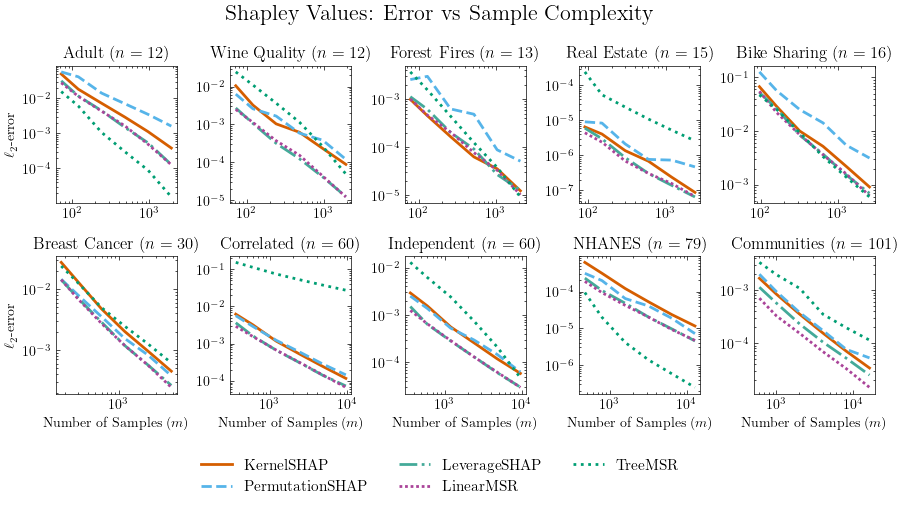

In [31]:
# Define datasets and parameters
extra_variable = 'sample_size'
extra_variable_vals = np.array([6, 10, 20, 40, 80, 160])
filter = {'sample_size': extra_variable_vals, 'noise': [0]}

# Load filtered error results
results = load_filtered_error(filter, extra_variable=extra_variable)

datasets = results.keys()  # Assuming results contain dataset keys
fig, axs = plt.subplots(2, len(datasets)//2, figsize=(9, 4.5))
all_handles = {}

# Iterate through datasets
# Sort the datasets by the number of samples
datasets = sorted(datasets, key=lambda x: dataset_sizes[x])
for j, dataset in enumerate(datasets):
    if 'shapley' not in results[dataset]:
        continue
    row = j // (len(datasets)//2)
    col = j % (len(datasets)//2)
    ax = axs[row, col]
    
    for estimator_idx, estimator in enumerate(use_estimators):

        if estimator not in results[dataset]['shapley']:
            continue
        
        errors = []
        for val in extra_variable_vals:
            adjusted_val = int(dataset_sizes[dataset] * val)
            errors.append(np.mean(results[dataset]['shapley'][estimator][adjusted_val]))

        line, = ax.plot(extra_variable_vals * dataset_sizes[dataset], errors,
                            label=estimator,
                            linestyle=linestyles[estimator_idx],
                            color=cb_colors[estimator_idx], linewidth=2)
        
        if estimator not in all_handles:
            all_handles[estimator] = line
    
    if col == 0:
        ax.set_ylabel(r'$\ell_2$-error')
    if row == 1:
        ax.set_xlabel('Number of Samples ($m$)')
    ax.set_yscale('log')
    ax.set_xscale('log')
    ax.set_title(f'{dataset} ($n={dataset_sizes[dataset]}$)')

# Overall figure title and legend
fig.suptitle('Shapley Values: Error vs Sample Complexity', fontsize=16)
fig.legend(all_handles.values(), all_handles.keys(), loc='upper center', 
           ncol=len(all_handles)//2+1, bbox_to_anchor=(0.5, 0), fontsize=11)
plt.tight_layout()
plt.savefig('images/shapley_sample_size.pdf', bbox_inches='tight', dpi=300)
plt.show()

In [32]:
def fancy_round(x, precision=2):
    return f"{x:.{precision}e}"

def one_big_table(results, filename, datasets, dataset_labels, use_estimators):
    # Each column is a dataset
    # There are several groups of rows: one for each method
    # Each group has 4 rows: mean, 1st quartile, 2nd quartile, 3rd quartile
    num_methods = len(use_estimators)
    table = np.zeros((num_methods*4, len(results)))
    for i, dataset in enumerate(datasets):
        for j, method in enumerate(use_estimators):
            values = np.array(results[dataset][method])
            mean = np.mean(values)
            median = np.median(values)
            upper = np.percentile(values, 75)
            lower = np.percentile(values, 25)
            to_add = np.array([mean, lower, median, upper])
            table[j*4:(j+1)*4, i] = to_add
    with open(filename, 'w') as f:
        f.write('\\resizebox{\\linewidth}{!}{ \n')
        f.write('\\begin{tabular} {l'+ 'c'*len(results) + '}\n')
        f.write('\\toprule\n')
        f.write(' & ' + ' & '.join([f'\\textbf{{{dataset}}}' for dataset in dataset_labels]) + ' \\\\ \n')
        f.write('\\midrule\n')
        i = 0
        for method in use_estimators:
            f.write('\\addlinespace[1ex] \n')
            f.write(f'\\textbf{{{method}}}' + ' & ' * len(results) + ' \\\\ \n')
            for metric in ['Mean', '1st Quartile', '2nd Quartile', '3rd Quartile']:
                row = [] 
                for j in range(len(results)):
                    # Color the best, second, third values with gold, silver, bronze
                    # Select every 4th row

                    relevant_col = sorted(table[(i%4)::4,j])
                    color = ''
                    if table[i,j] == relevant_col[0]:
                        color = '\\cellcolor{gold!60}'
                    elif table[i,j] == relevant_col[1]:
                        color = '\\cellcolor{silver!60}'
                    elif table[i,j] == relevant_col[2]:
                        color = '\\cellcolor{bronze!60}'
                    row += [color + str(fancy_round(table[i,j]))]
                start = '\\hspace{7pt}' + metric + ' & '
                f.write(start + ' & '.join([str(x) for x in row]) + ' \\\\ \n')
                i += 1
        f.write('\\bottomrule\n')
        f.write('\\end{tabular}}') 

# Load filtered error results
results = load_filtered_error(
    {'sample_size': [10], 'noise': [0]}
)

# Remove shapley
for dataset in results:
    if 'shapley' in results[dataset]:
        results[dataset] = results[dataset]['shapley']
    else:
        del results[dataset]

one_big_table(results, 'tables/shapley.tex', datasets, datasets, use_estimators)

/var/folders/qq/hk_0lt914qn6ny3hn40bvg3r0000gn/T/ipykernel_57979/942265144.py:27: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  plt.tight_layout()


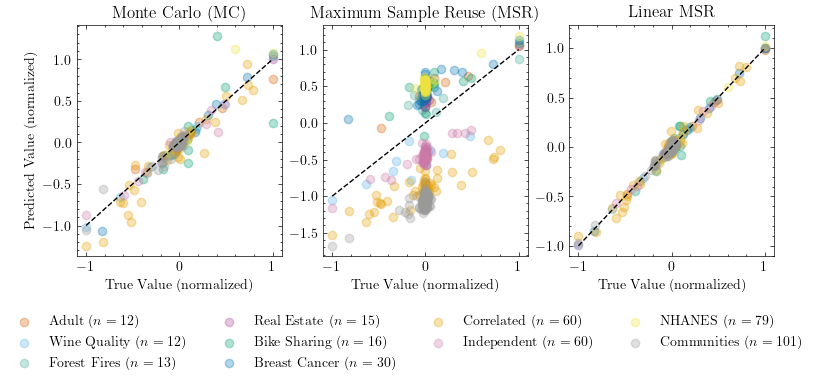

In [33]:
use_estimators = ['WSL', 'MSR', 'LinearMSR']
estimator_lookup = {'WSL': 'Monte Carlo (MC)', 'MSR': 'Maximum Sample Reuse (MSR)', 'LinearMSR': 'Linear MSR'}

fig, axs = plt.subplots(1, len(use_estimators), figsize=(9, 3))

for j, dataset in enumerate(datasets):
    filename = f'output/case_study_{dataset}.csv'
    with open(filename, 'r') as f:
        for line in f:
            dict = eval(line.replace('array', 'np.array'))
        true_values = dict['True'][0]
        max_val = np.max(np.abs(true_values))

        for i, estimator in enumerate(use_estimators):
            pred_values = dict[estimator]
            axs[i].scatter(true_values/max_val, pred_values/max_val, label=rf'{dataset} ($n={dataset_sizes[dataset]}$)', color=cb_colors[j], alpha=0.3, marker='o')

for i, estimator in enumerate(use_estimators):
    # Draw the diagonal line
    axs[i].plot([-1, 1], [-1, 1], linestyle='--', color='black', linewidth=1, alpha=1)
    axs[i].set_title(f'{estimator_lookup[estimator]}')
    axs[i].set_xlabel('True Value (normalized)')
    if i == 0:
        axs[i].set_ylabel('Predicted Value (normalized)')

plt.legend(fancybox=True, bbox_to_anchor=(1.2,-.2), ncol=4)
plt.tight_layout()
plt.savefig('images/case_study.pdf', bbox_inches='tight', dpi=300)
            


### Probabilistic Values

In [34]:
# Load filtered error results
results = load_filtered_error(
    {'sample_size': [10], 'noise': [0]}
)

def combine_datasets(results, dataset_group=None):
    fixed_dataset = 'Communities' # used for finding weights, estimators
    new_results = {
        weight: {
            estimator : [] for estimator in results[fixed_dataset][weight]
        } for weight in results[fixed_dataset]
    }
    for weight in results[fixed_dataset]:
        for estimator in results[fixed_dataset][weight]:
            errors = []
            for dataset in results.keys():
                if dataset_group is not None:
                    if dataset not in DATASETS[dataset_group]: continue
                errors += results[dataset][weight][estimator]
            new_results[weight][estimator] = errors
    return new_results

use_estimators = ESTIMATOR_ALL.keys()

for dataset_group in ['small_n', 'big_n']:
    combined_results = combine_datasets(results, dataset_group)

    weights = weightings['Symmetric Beta'] + weightings['Asymmetric Beta'][1:] + weightings['Weighted Banzhaf']
    weights_labels = [weight_lookup[weight] for weight in weights]

    one_big_table(combined_results, f'tables/probabilistic_{dataset_group}.tex', weights, weights_labels, use_estimators)

['beta_shapley_1_1', 'beta_shapley_2_2', 'beta_shapley_4_4', 'beta_shapley_8_8', 'beta_shapley_16_16']
['beta_shapley_1_1', 'beta_shapley_1_2', 'beta_shapley_1_4', 'beta_shapley_1_8', 'beta_shapley_1_16']
['weighted_banzhaf_0.5', 'weighted_banzhaf_0.6', 'weighted_banzhaf_0.7', 'weighted_banzhaf_0.8', 'weighted_banzhaf_0.9']


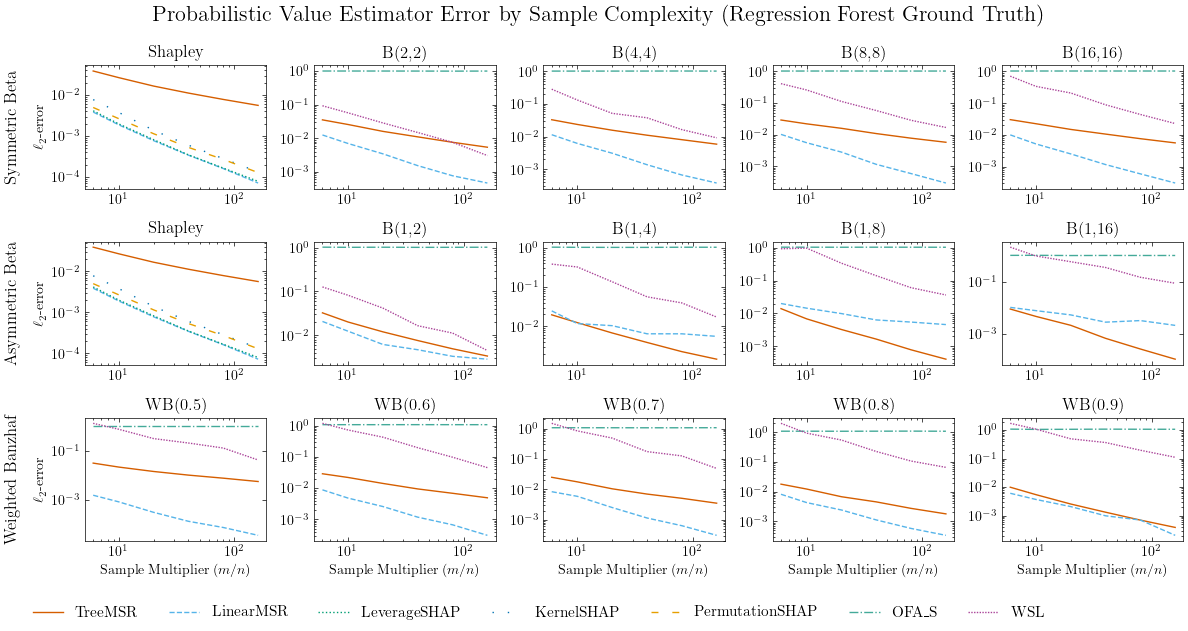

['beta_shapley_1_1', 'beta_shapley_2_2', 'beta_shapley_4_4', 'beta_shapley_8_8', 'beta_shapley_16_16']
['beta_shapley_1_1', 'beta_shapley_1_2', 'beta_shapley_1_4', 'beta_shapley_1_8', 'beta_shapley_1_16']
['weighted_banzhaf_0.5', 'weighted_banzhaf_0.6', 'weighted_banzhaf_0.7', 'weighted_banzhaf_0.8', 'weighted_banzhaf_0.9']


<Figure size 350x262.5 with 0 Axes>

In [35]:
# Make a giant plot
# The columns are the datasets
# The rows are the weightings i.e., beta_shapley_sym, beta_shapley_asym, weighted_banzhaf
# Each subplot is a line plot of the error for each estimator and the x axis is the number of samples on one of the weightings in the class of the row

fig, axs = plt.subplots(len(weightings), 5, figsize=(12, 6))


extra_variable = 'sample_size'
extra_variable_vals = VARIABLES['sample_size']['sample_size']

filter = {
    'sample_size' : extra_variable_vals,
    'noise' : [0],
}

results = load_filtered_error(filter, extra_variable=extra_variable)

for dataset_group in ['big_n', 'small_n']:

    all_handles = {}
    for i, (weight_list_name, weight_list) in enumerate(weightings.items()):
        print(weight_list)
        for j, weight in enumerate(weight_list):
            if weight == 'beta_shapley_1_1':
                weight = 'shapley'
            for estimator_idx, estimator in enumerate(ESTIMATOR_FACTORY.keys()):
                if weight not in results[dataset]: continue
                if estimator not in results[dataset][weight]: continue
                errors = {'mean':[], 'median':[], '1st':[], '3rd':[]}
                for val in extra_variable_vals:
                    val_errors = []
                    for dataset in DATASETS[dataset_group]:
                        if extra_variable == 'sample_size':
                            actual_sample_size = int(dataset_sizes[dataset]*val) 
                        val_errors += [np.mean(results[dataset][weight][estimator][actual_sample_size])]
                    errors['mean'].append(np.mean(val_errors))
                    errors['median'].append(np.median(val_errors))
                    errors['1st'].append(np.percentile(val_errors, 25))
                    errors['3rd'].append(np.percentile(val_errors, 75))

                line, = axs[i, j].plot(
                    extra_variable_vals, errors['mean'], 
                    label=estimator, 
                    linestyle=linestyles[estimator_idx], 
                    color=cb_colors[estimator_idx]
                )

                # Add the line handle to the global collection
                if estimator not in all_handles:
                    all_handles[estimator] = line
            axs[i, j].set_yscale('log')
            axs[i, j].set_xscale('log')
            axs[i, j].set_title(weight_lookup[weight])
            if i == 2:
                axs[i,j].set_xlabel(r'Sample Multiplier ($m/n$)')
            if j == 0:
                axs[i,j].set_ylabel(r'$\ell_2$-error')
                axs[i,j].annotate(weight_list_name,
                xy=(-.4, 0.5),              # Coordinates in axis fraction
                xycoords='axes fraction', # Relative to the axis
                fontsize=12,
                rotation=90,              # Rotate to align with y-axis
                ha='center',              # Centered horizontally
                va='center',              # Centered vertically
                color='black')

    nice_group_name = {'small_n' : r'(Neural Net Ground Truth)', 'big_n' : r'(Regression Forest Ground Truth)'}[dataset_group]

    fig.suptitle(f'Probabilistic Value Estimator Error by Sample Complexity ' + nice_group_name, fontsize=16)
    # Two layers of legends
    fig.legend(all_handles.values(), all_handles.keys(), loc='upper center', ncol=8, bbox_to_anchor=(0.45,0), fontsize=11)
    plt.tight_layout()
    plt.savefig(f'images/prob_complexity_{dataset_group}.pdf', dpi=300)
    plt.show()

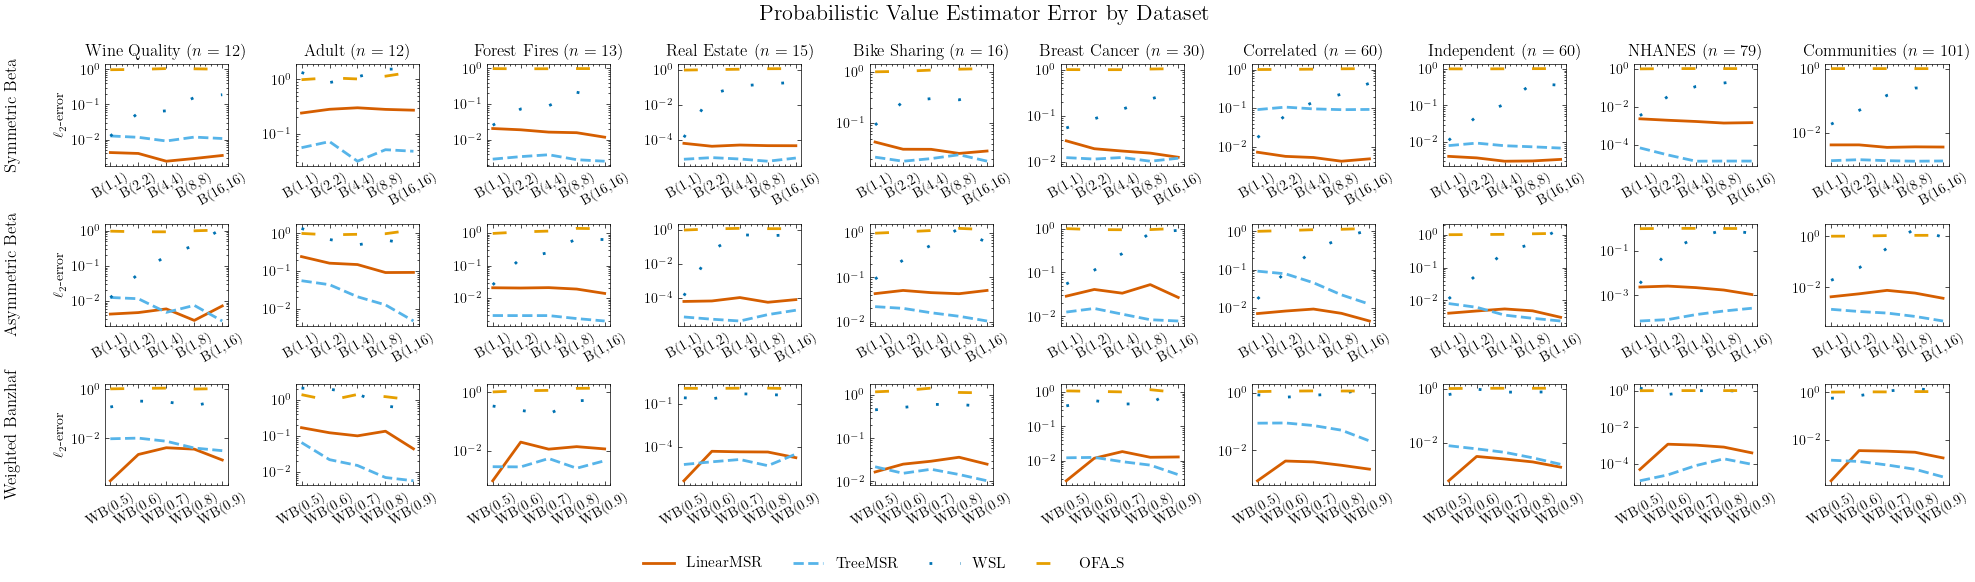

In [36]:
# Make a giant plot
# The columns are the datasets
# The rows are the weightings i.e., beta_shapley_sym, beta_shapley_asym, weighted_banzhaf
# Each subplot is a line plot of the error for each estimator

filter = {
    'sample_size' : [10],
    'noise' : [0]
}
results = load_filtered_error(filter)

use_estimators = [
    'LinearMSR',
    'TreeMSR',
    'LeverageSHAP',
    'PermutationSHAP',
    'KernelSHAP', 
    'WSL',
    'OFA_S',
]

filename = 'images/prob_datasets.pdf'


fig, axs = plt.subplots(len(weightings), len(dataset_names), figsize=(20, 5.5))

all_handles = {}
for i, (weight_list_name, weight_list) in enumerate(weightings.items()):
    for j, dataset in enumerate(dataset_names):
        if i == 0:
            axs[i, j].set_title(fr'{dataset} ($n={dataset_sizes[dataset]}$)')
        if j == 0:
            axs[i, j].set_ylabel(fr'$\ell_2$-error')
            axs[i,j].annotate(weight_list_name,
                xy=(-.75, 0.5),              # Coordinates in axis fraction
                xycoords='axes fraction', # Relative to the axis
                fontsize=12,
                rotation=90,              # Rotate to align with y-axis
                ha='center',              # Centered horizontally
                va='center',              # Centered vertically
                color='black')
        for estimator_idx, estimator in enumerate(use_estimators):
            if weight_list[-2] not in results[dataset]:
                continue
            if estimator not in results[dataset][weight_list[-2]]:
                continue
            errors = [np.mean(results[dataset][weighting][estimator]) for weighting in weight_list]
            prettier_weight_list = [weight_lookup[weighting] for weighting in weight_list]
        
            # Rotate the x-axis labels
            axs[i, j].set_xticks(np.arange(len(prettier_weight_list)))
            axs[i, j].set_xticklabels(prettier_weight_list, rotation=30)
            line, = axs[i, j].plot(prettier_weight_list, errors, 
                                label=estimator, 
                                linestyle=linestyles[estimator_idx], 
                                color=cb_colors[estimator_idx], linewidth=2)

            # Add the line handle to the global collection
            if estimator not in all_handles:
                all_handles[estimator] = line
        axs[i, j].set_yscale('log')

fig.suptitle('Probabilistic Value Estimator Error by Dataset', fontsize=16)
# Two layers of legends
fig.legend(all_handles.values(), all_handles.keys(), loc='upper center', ncol=len(all_handles), bbox_to_anchor=(0.45,0), fontsize=11)

plt.tight_layout()

plt.savefig(filename, bbox_inches='tight', dpi=300)
plt.show()

## Quality of Fit

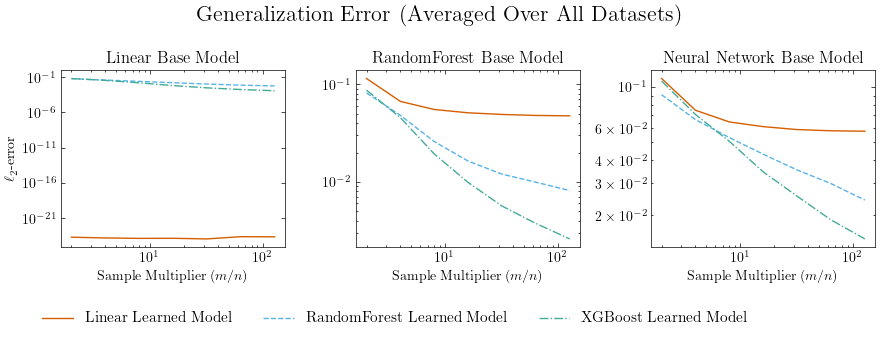

In [37]:

# The columns are the ground_truth_class
# Each subplot is a line plot of the error for reg_model_class and the x axis is the number of samples

fig, axs = plt.subplots(1, 3, figsize=(9, 3))

all_handles = {}
for i, ground_truth_class in enumerate(['Linear', 'RandomForest', 'NeuralNet']):
    fit_errors = {}
    for j, dataset in enumerate(dataset_names):
        fit_errors_dataset = load_fit_error(dataset, ground_truth_class)
        for estimator in fit_errors_dataset:
            if estimator not in fit_errors:
                fit_errors[estimator] = {}
            for sample_multiplier in fit_errors_dataset[estimator]:
                if sample_multiplier not in fit_errors[estimator]:
                    fit_errors[estimator][sample_multiplier] = []
                fit_errors[estimator][sample_multiplier] += fit_errors_dataset[estimator][sample_multiplier]

    for reg_model_class_idx, reg_model_class in enumerate(fit_errors.keys()):
        errors = []
        sample_multipliers = []
        for val in fit_errors[reg_model_class]:
            errors.append(np.mean(fit_errors[reg_model_class][val]))
            sample_multipliers += [val]

        line, = axs[i].plot(sample_multipliers, errors, 
            label=reg_model_class + ' Learned Model', 
            linestyle=linestyles[reg_model_class_idx], 
            color=cb_colors[reg_model_class_idx])

        # Add the line handle to the global collection
        if reg_model_class not in all_handles:
            all_handles[reg_model_class + ' Learned Model'] = line
    axs[i].set_yscale('log')
    axs[i].set_xscale('log')
    if ground_truth_class == 'NeuralNet':
        ground_truth_class = 'Neural Network'
    axs[i].set_title(fr'{ground_truth_class} Base Model')
    if i == 0:
        axs[i].set_ylabel(fr'$\ell_2$-error')

    axs[i].set_xlabel(r'Sample Multiplier ($m/n$)')


fig.suptitle(f'Generalization Error (Averaged Over All Datasets)', fontsize=16)
# Two layers of legends
fig.legend(all_handles.values(), all_handles.keys(), loc='upper center', ncol=len(all_handles), bbox_to_anchor=(0.45,0), fontsize=11)

plt.tight_layout()
plt.savefig('images/fit_sample_complexity.pdf', bbox_inches='tight', dpi=300)
plt.show()

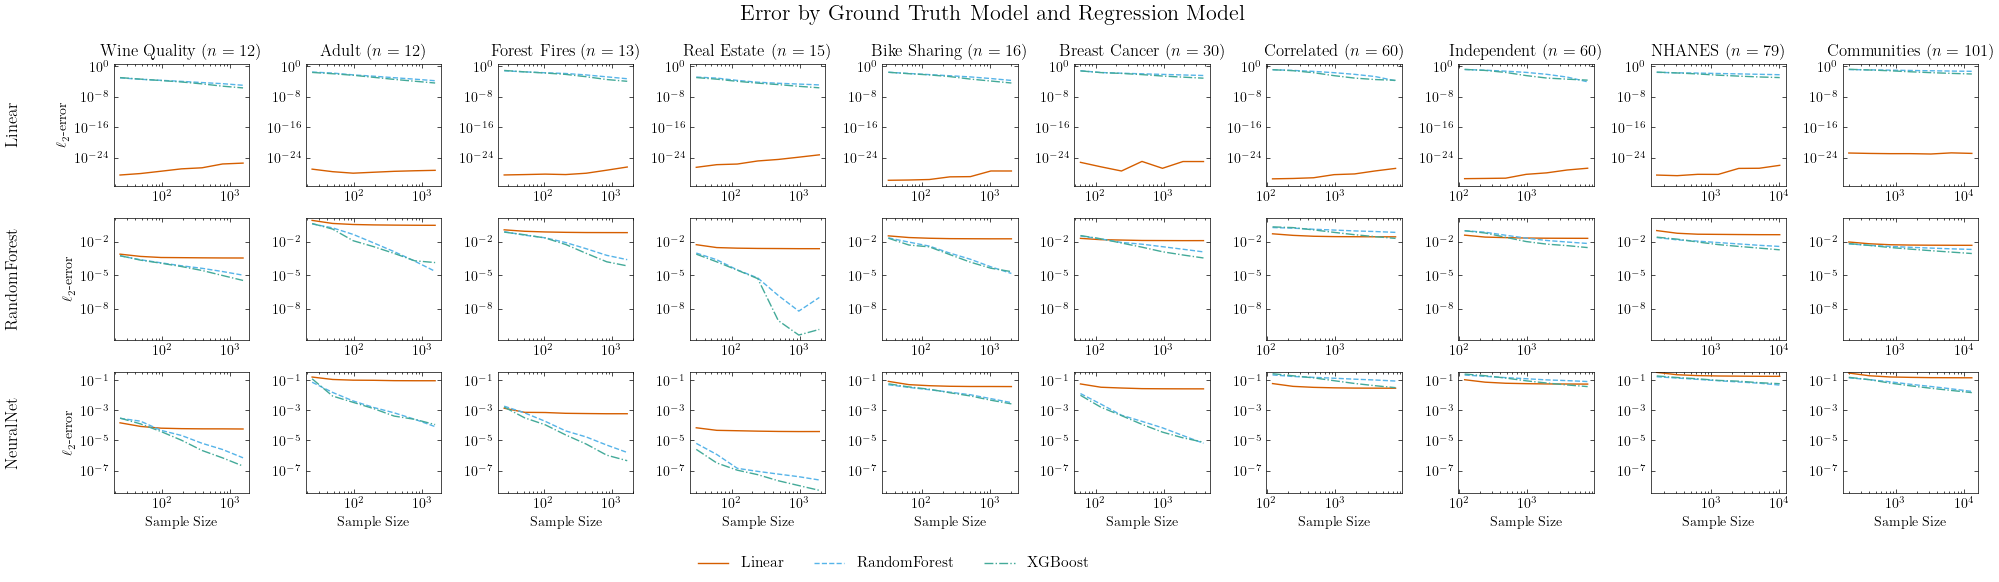

In [38]:
# Make a giant plot
# The columns are the datasets
# The rows are the ground_truth_class
# Each subplot is a line plot of the error for reg_model_class and the x axis is the number of samples

fig, axs = plt.subplots(3, 10, figsize=(20, 5.5))

all_handles = {}
for i, ground_truth_class in enumerate(['Linear', 'RandomForest', 'NeuralNet']):
    for j, dataset in enumerate(dataset_names):
        fit_errors = load_fit_error(dataset, ground_truth_class)
        for reg_model_class_idx, reg_model_class in enumerate(fit_errors.keys()):
            errors = []
            num_samples = []
            for val in fit_errors[reg_model_class]:
                errors.append(np.mean(fit_errors[reg_model_class][val]))
                num_samples += [int(dataset_sizes[dataset]*val)]

            line, = axs[i, j].plot(num_samples, errors, 
                                   label=reg_model_class, 
                                   linestyle=linestyles[reg_model_class_idx], 
                                   color=cb_colors[reg_model_class_idx])

            # Add the line handle to the global collection
            if reg_model_class not in all_handles:
                all_handles[reg_model_class] = line
        axs[i, j].set_yscale('log')
        axs[i, j].set_xscale('log')
        if i == 0:
            axs[i, j].set_title(fr'{dataset} ($n={dataset_sizes[dataset]}$)')
        if j == 0:
            axs[i, j].set_ylabel(fr'$\ell_2$-error')
            axs[i,j].annotate(ground_truth_class,
                xy=(-.75, 0.5),              # Coordinates in axis fraction
                xycoords='axes fraction', # Relative to the axis
                fontsize=12,
                rotation=90,              # Rotate to align with y-axis
                ha='center',              # Centered horizontally
                va='center',              # Centered vertically
                color='black')
        if i == 2:
            axs[i, j].set_xlabel('Sample Size')


fig.suptitle(f'Error by Ground Truth Model and Regression Model', fontsize=16)
# Two layers of legends
fig.legend(all_handles.values(), all_handles.keys(), loc='upper center', ncol=len(all_handles), bbox_to_anchor=(0.45,0), fontsize=11)
for i in range(3):
    ylims = [ax.get_ylim() for ax in axs[i, :]]

    shared_ylim = (min(y[0] for y in ylims), max(y[1] for y in ylims))

    for ax in axs[i, :]:
        ax.set_ylim(shared_ylim)

plt.tight_layout()
plt.savefig('images/fit_datasets.pdf', bbox_inches='tight', dpi=300)
plt.show()